# Laboratorium 2 — Sieci rekurencyjne: budowa i uczenie



### Import i ustawienia

In [ ]:
import time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

np.random.seed(0)
torch.manual_seed(0)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
if DEVICE == 'cpu':
    torch.set_num_threads(2)
print('Urządzenie:', DEVICE)


Urządzenie: cpu


###Generowanie szeregu czasowego

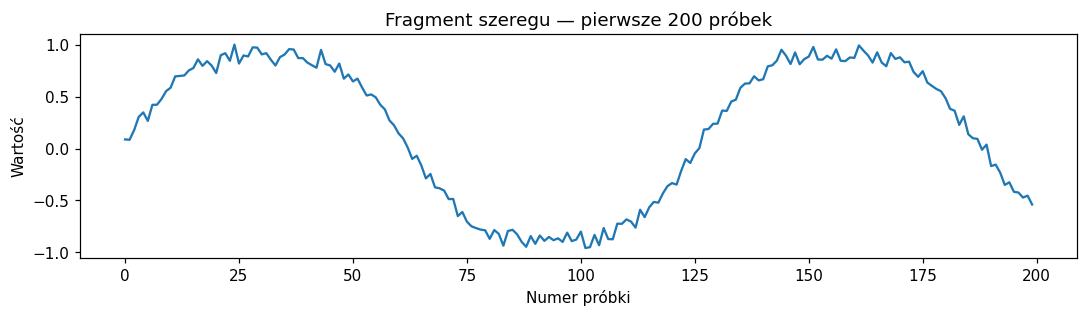

In [ ]:
def generuj_szereg(n=2000):
    t = np.linspace(0, 100, n)
    y = np.sin(t) + 0.1 * np.sin(3 * t) + 0.05 * np.random.randn(n)
    return y.astype(np.float32)

seria = generuj_szereg()
plt.figure(figsize=(10, 3))
plt.plot(seria[:200])
plt.title('Fragment szeregu — pierwsze 200 próbek')
plt.xlabel('Numer próbki')
plt.ylabel('Wartość')
plt.tight_layout()
plt.show()


### Tworzenie okien i chronologiczny podział danych

In [ ]:
def zrob_okna(seria, okno=30):
    X, Y = [], []
    for i in range(len(seria) - okno):
        X.append(seria[i:i + okno])
        Y.append(seria[i + okno])
    X = np.array(X, dtype=np.float32)[..., None]
    Y = np.array(Y, dtype=np.float32)[:, None]
    return X, Y


def przygotuj_dane(seria, okno):
    X, Y = zrob_okna(seria, okno)
    n_tr = int(0.8 * len(X))
    Xtr = torch.tensor(X[:n_tr], device=DEVICE)
    Ytr = torch.tensor(Y[:n_tr], device=DEVICE)
    Xte = torch.tensor(X[n_tr:], device=DEVICE)
    Yte = torch.tensor(Y[n_tr:], device=DEVICE)
    return Xtr, Ytr, Xte, Yte

OKNO = 30
Xtr, Ytr, Xte, Yte = przygotuj_dane(seria, OKNO)
print('OKNO:', OKNO, '| Trening:', tuple(Xtr.shape), '| Test:', tuple(Xte.shape))


OKNO: 30 | Trening: (1576, 30, 1) | Test: (394, 30, 1)


### Definicja modelu RNN / LSTM / GRU

In [ ]:
class ModelRNN(nn.Module):
    def __init__(self, hidden=32, typ='RNN'):
        super().__init__()
        rnn = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[typ]
        self.rnn = rnn(input_size=1, hidden_size=hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])


def licz_parametry(model):
    return sum(p.numel() for p in model.parameters())


### Funkcja treningu — strata treningowa i testowa

In [ ]:
def trenuj(model, Xtr, Ytr, Xte, Yte, epoki=20, lr=1e-2, batch=64):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    strata = nn.MSELoss()
    hist_test, hist_trening = [], []
    n = len(Xtr)

    for ep in range(epoki):
        model.train()
        perm = torch.randperm(n, device=DEVICE)
        for i in range(0, n, batch):
            idx = perm[i:i + batch]
            opt.zero_grad()
            loss = strata(model(Xtr[idx]), Ytr[idx])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()

        model.eval()
        with torch.no_grad():
            hist_trening.append(strata(model(Xtr), Ytr).item())
            hist_test.append(strata(model(Xte), Yte).item())

    return hist_test, hist_trening


### Model bazowy — RNN, hidden=32, OKNO=30, 30 epok

Bazowy RNN (hidden=32, OKNO=30, 30 epok):
  test MSE po 1. epoce: 0.007788
  test MSE po 30. epoce: 0.003769
  średnie test MSE z 5 ostatnich epok: 0.003857


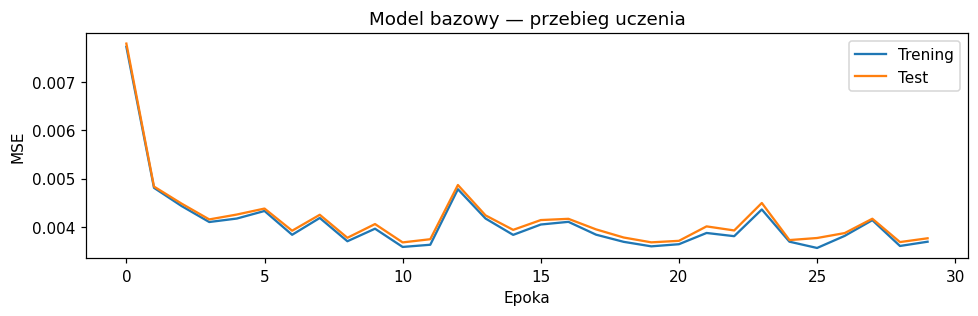

In [ ]:
torch.manual_seed(0)
model_bazowy = ModelRNN(hidden=32, typ='RNN')
hist_baz_test, hist_baz_tr = trenuj(
    model_bazowy, Xtr, Ytr, Xte, Yte, epoki=30, lr=1e-2, batch=64
)
print(f'Bazowy RNN (hidden=32, OKNO=30, 30 epok):')
print(f'  test MSE po 1. epoce: {hist_baz_test[0]:.6f}')
print(f'  test MSE po 30. epoce: {hist_baz_test[-1]:.6f}')
print(f'  średnie test MSE z 5 ostatnich epok: {np.mean(hist_baz_test[-5:]):.6f}')
plt.figure(figsize=(9, 3))
plt.plot(hist_baz_tr, label='Trening')
plt.plot(hist_baz_test, label='Test')
plt.title('Model bazowy — przebieg uczenia')
plt.xlabel('Epoka')
plt.ylabel('MSE')
plt.legend()
plt.tight_layout()
plt.show()


### Heurystyka „ostatnia próbka” — wszystkie okna

In [ ]:
heurystyki = {}
for okno in [10, 30, 60, 120]:
    _, _, Xte_w, Yte_w = przygotuj_dane(seria, okno)
    heurystyki[okno] = ((Yte_w - Xte_w[:, -1]) ** 2).mean().item()
    print(f'OKNO={okno:3d} | test MSE heurystyki = {heurystyki[okno]:.6f}')


OKNO= 10 | test MSE heurystyki = 0.006281
OKNO= 30 | test MSE heurystyki = 0.006309
OKNO= 60 | test MSE heurystyki = 0.006331
OKNO=120 | test MSE heurystyki = 0.006313


### Hipotezy przed eksperymentami

- **A:** Więcej jednostek ukrytych może poprawić MSE, ale zależność nie musi być monotoniczna, a liczba parametrów i czas treningu wzrosną.
- **B:** Wydłużenie okna GRU z 10 do 60 kroków poprawi prognozę, natomiast powiększenie go do 120 nie musi przynieść dalszego zysku.


### Wspólna procedura eksperymentów (3 ziarna)

In [ ]:
wyniki = {}
modele_seed0 = {}


def uruchom(typ, hidden, okno):
    klucz = (typ, hidden, okno)
    if klucz in wyniki:
        return wyniki[klucz]

    Xtr_w, Ytr_w, Xte_w, Yte_w = przygotuj_dane(seria, okno)
    powtorzenia = []
    for seed in [0, 1, 2]:
        torch.manual_seed(seed)
        if DEVICE == 'cuda':
            torch.cuda.manual_seed_all(seed)
        model = ModelRNN(hidden=hidden, typ=typ)
        start = time.perf_counter()
        hist_test, hist_tr = trenuj(
            model, Xtr_w, Ytr_w, Xte_w, Yte_w,
            epoki=20, lr=1e-2, batch=64
        )
        czas = time.perf_counter() - start
        powtorzenia.append({
            'seed': seed,
            'mse': float(np.mean(hist_test[-5:])),
            'hist_test': hist_test,
            'hist_tr': hist_tr,
            'czas': czas
        })
        if seed == 0:
            modele_seed0[klucz] = model

    wyniki[klucz] = {
        'parametry': licz_parametry(model),
        'mse_srednia': float(np.mean([p['mse'] for p in powtorzenia])),
        'mse_std': float(np.std([p['mse'] for p in powtorzenia])),
        'czas_sredni': float(np.mean([p['czas'] for p in powtorzenia])),
        'powtorzenia': powtorzenia
    }
    return wyniki[klucz]


def wypisz_tabele(konfiguracje, okna_heurystyki):
    print('Konfiguracja             | Parametry | MSE średnia ± odch.     | Czas średni [s]')
    print('-' * 81)
    for okno in okna_heurystyki:
        print(f'Heurystyka OKNO={okno:<3d}      |      -    | {heurystyki[okno]:.6f}              | -')
    for typ, hidden, okno in konfiguracje:
        w = wyniki[(typ, hidden, okno)]
        print(f'{typ:4s}, h={hidden:<2d}, OKNO={okno:<3d} | {w["parametry"]:>9d} | '
              f'{w["mse_srednia"]:.6f} ± {w["mse_std"]:.6f} | '
              f'{w["czas_sredni"]:>9.2f}')


### Eksperyment A — liczba jednostek ukrytych

In [ ]:
konf_A = [('GRU', hidden, 30) for hidden in [8, 16, 32, 64]]
for typ, hidden, okno in konf_A:
    uruchom(typ, hidden, okno)
print('EKSPERYMENT A — GRU, OKNO=30')
wypisz_tabele(konf_A, [30])


EKSPERYMENT A — GRU, OKNO=30
Konfiguracja             | Parametry | MSE średnia ± odch.     | Czas średni [s]
---------------------------------------------------------------------------------
Heurystyka OKNO=30       |      -    | 0.006309              | -
GRU , h=8 , OKNO=30  |       273 | 0.003797 ± 0.000045 |      2.37
GRU , h=16, OKNO=30  |       929 | 0.003737 ± 0.000021 |      2.74
GRU , h=32, OKNO=30  |      3393 | 0.003761 ± 0.000012 |      3.44
GRU , h=64, OKNO=30  |     12929 | 0.003751 ± 0.000082 |      5.30


### Eksperyment B — długość okna

In [ ]:
konf_B = [('GRU', 32, okno) for okno in [10, 30, 60, 120]]
for typ, hidden, okno in konf_B:
    uruchom(typ, hidden, okno)
print('EKSPERYMENT B — GRU, hidden=32')
wypisz_tabele(konf_B, [10, 30, 60, 120])


EKSPERYMENT B — GRU, hidden=32
Konfiguracja             | Parametry | MSE średnia ± odch.     | Czas średni [s]
---------------------------------------------------------------------------------
Heurystyka OKNO=10       |      -    | 0.006281              | -
Heurystyka OKNO=30       |      -    | 0.006309              | -
Heurystyka OKNO=60       |      -    | 0.006331              | -
Heurystyka OKNO=120      |      -    | 0.006313              | -
GRU , h=32, OKNO=10  |      3393 | 0.004138 ± 0.000187 |      1.39
GRU , h=32, OKNO=30  |      3393 | 0.003761 ± 0.000012 |      3.44
GRU , h=32, OKNO=60  |      3393 | 0.003425 ± 0.000212 |      6.12
GRU , h=32, OKNO=120 |      3393 | 0.003437 ± 0.000186 |     12.37


### Eksperyment C — typ komórki dla okien 10 i 120

In [ ]:
konf_C = [(typ, 32, okno)
          for okno in [10, 120]
          for typ in ['RNN', 'LSTM', 'GRU']]
for typ, hidden, okno in konf_C:
    uruchom(typ, hidden, okno)
print('EKSPERYMENT C — hidden=32, OKNO=10 oraz 120')
wypisz_tabele(konf_C, [10, 120])


EKSPERYMENT C — hidden=32, OKNO=10 oraz 120
Konfiguracja             | Parametry | MSE średnia ± odch.     | Czas średni [s]
---------------------------------------------------------------------------------
Heurystyka OKNO=10       |      -    | 0.006281              | -
Heurystyka OKNO=120      |      -    | 0.006313              | -
RNN , h=32, OKNO=10  |      1153 | 0.004171 ± 0.000246 |      0.73
LSTM, h=32, OKNO=10  |      4513 | 0.004151 ± 0.000112 |      0.82
GRU , h=32, OKNO=10  |      3393 | 0.004138 ± 0.000187 |      1.39
RNN , h=32, OKNO=120 |      1153 | 0.004003 ± 0.000008 |      4.85
LSTM, h=32, OKNO=120 |      4513 | 0.003748 ± 0.000135 |      6.45
GRU , h=32, OKNO=120 |      3393 | 0.003437 ± 0.000186 |     12.37


### Wybór najlepszej konfiguracji

In [ ]:
wszystkie_konf = list(dict.fromkeys(konf_A + konf_B + konf_C))
najlepsza = min(wszystkie_konf, key=lambda k: wyniki[k]['mse_srednia'])
w_naj = wyniki[najlepsza]
print('Najlepsza konfiguracja według średniego test MSE:')
print(f'  typ={najlepsza[0]}, hidden={najlepsza[1]}, OKNO={najlepsza[2]}')
print(f'  MSE = {w_naj["mse_srednia"]:.6f} ± {w_naj["mse_std"]:.6f}')
print(f'  liczba parametrów = {w_naj["parametry"]}')
print(f'  średni czas = {w_naj["czas_sredni"]:.2f} s')
print(f'  heurystyka dla OKNO={najlepsza[2]}: {heurystyki[najlepsza[2]]:.6f}')


Najlepsza konfiguracja według średniego test MSE:
  typ=GRU, hidden=32, OKNO=60
  MSE = 0.003425 ± 0.000212
  liczba parametrów = 3393
  średni czas = 6.12 s
  heurystyka dla OKNO=60: 0.006331


### Wykresy straty testowej — eksperymenty A, B, C

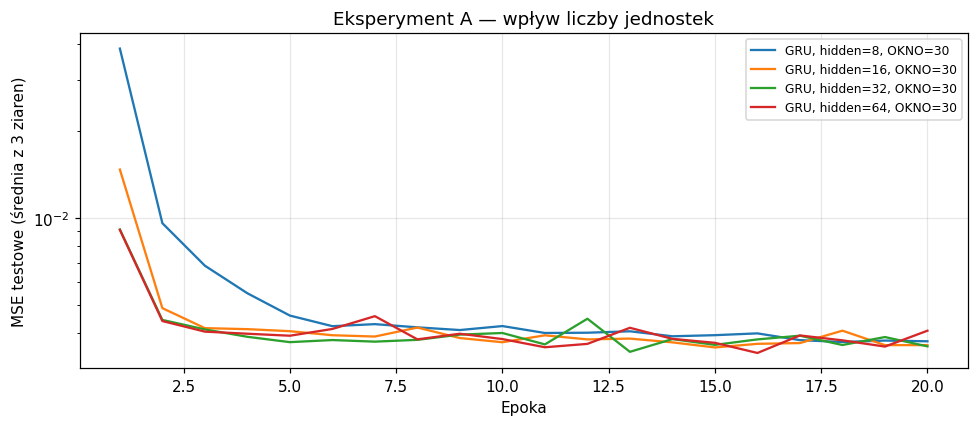

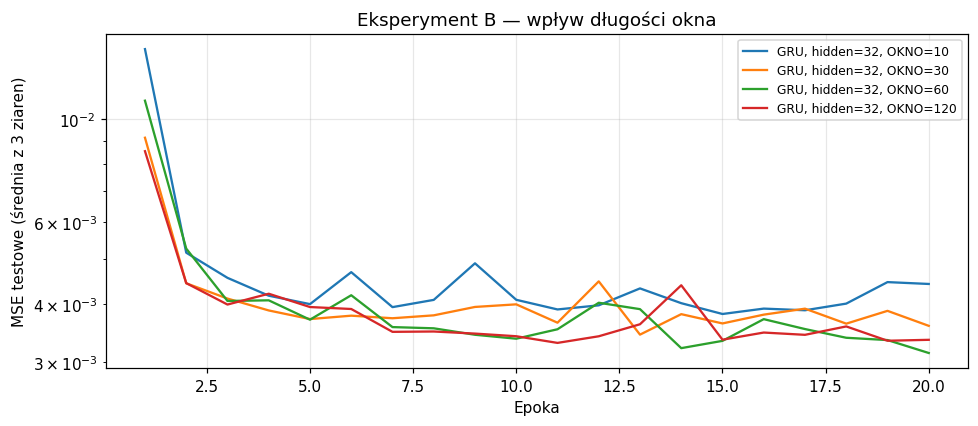

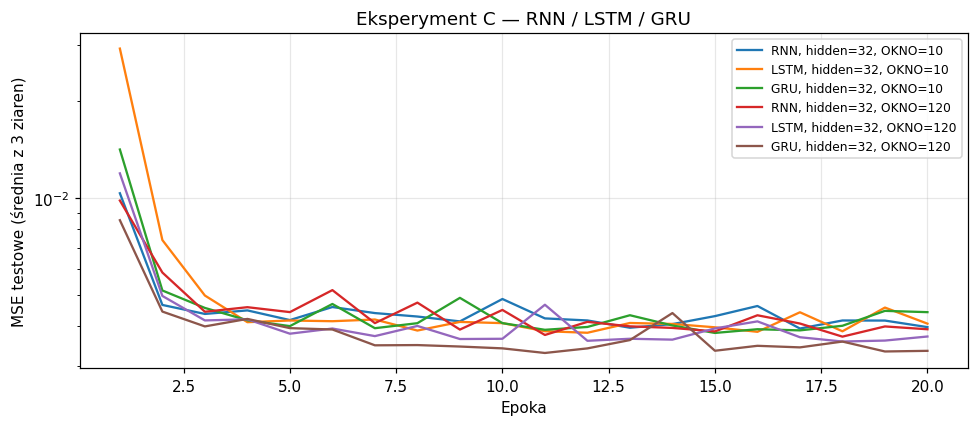

In [ ]:
def wykres_eksperymentu(konfiguracje, tytul):
    plt.figure(figsize=(9, 4))
    for typ, hidden, okno in konfiguracje:
        w = wyniki[(typ, hidden, okno)]
        srednia_hist = np.mean(
            [p['hist_test'] for p in w['powtorzenia']], axis=0
        )
        plt.plot(range(1, 21), srednia_hist,
                 label=f'{typ}, hidden={hidden}, OKNO={okno}')
    plt.title(tytul)
    plt.xlabel('Epoka')
    plt.ylabel('MSE testowe (średnia z 3 ziaren)')
    plt.yscale('log')
    plt.legend(fontsize=8)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

wykres_eksperymentu(konf_A, 'Eksperyment A — wpływ liczby jednostek')
wykres_eksperymentu(konf_B, 'Eksperyment B — wpływ długości okna')
wykres_eksperymentu(konf_C, 'Eksperyment C — RNN / LSTM / GRU')


### Najlepsza konfiguracja — strata treningowa i testowa

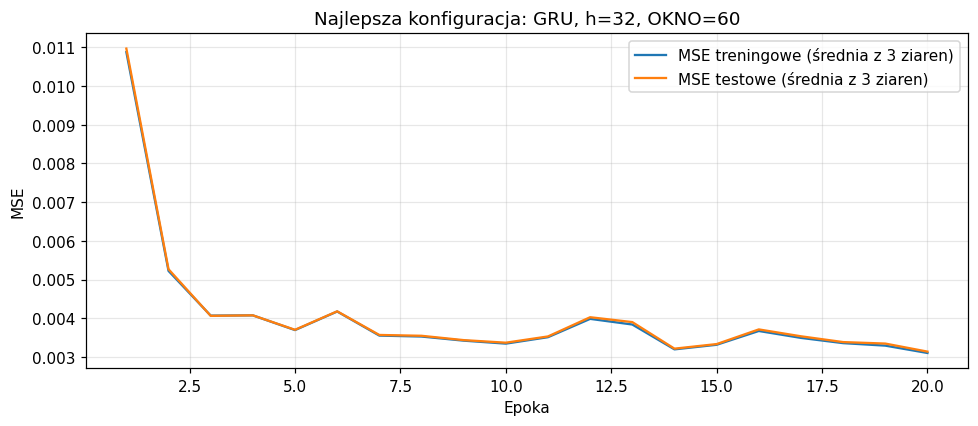

In [ ]:
powt = w_naj['powtorzenia']
sr_tr = np.mean([p['hist_tr'] for p in powt], axis=0)
sr_te = np.mean([p['hist_test'] for p in powt], axis=0)
plt.figure(figsize=(9, 4))
plt.plot(range(1, 21), sr_tr, label='MSE treningowe (średnia z 3 ziaren)')
plt.plot(range(1, 21), sr_te, label='MSE testowe (średnia z 3 ziaren)')
plt.xlabel('Epoka')
plt.ylabel('MSE')
plt.title(f'Najlepsza konfiguracja: {najlepsza[0]}, h={najlepsza[1]}, OKNO={najlepsza[2]}')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Najlepsza konfiguracja — predykcja 200 próbek testowych

Predykcja: model otrzymuje prawdziwe poprzednie próbki (nie prognozuje rekurencyjnie wielu kroków).


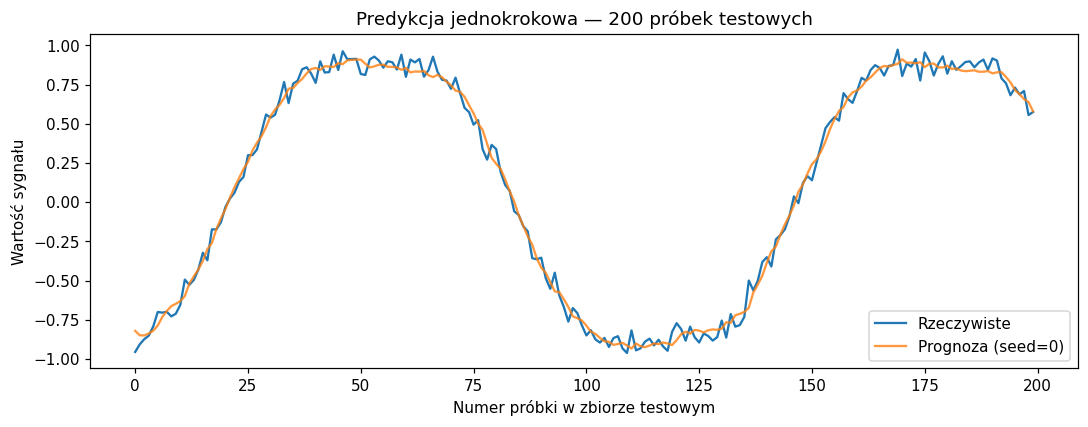

In [ ]:
_, _, Xte_best, Yte_best = przygotuj_dane(seria, najlepsza[2])
model_best = modele_seed0[najlepsza]
model_best.eval()
with torch.no_grad():
    pred = model_best(Xte_best).cpu().numpy().ravel()
prawdziwe = Yte_best.cpu().numpy().ravel()

plt.figure(figsize=(10, 4))
plt.plot(prawdziwe[:200], label='Rzeczywiste')
plt.plot(pred[:200], label='Prognoza (seed=0)', alpha=0.8)
plt.xlabel('Numer próbki w zbiorze testowym')
plt.ylabel('Wartość sygnału')
plt.title('Predykcja jednokrokowa — 200 próbek testowych')
plt.legend()
plt.tight_layout()
plt.show()
print('Predykcja: model otrzymuje prawdziwe poprzednie próbki (nie prognozuje rekurencyjnie wielu kroków).')


## Uwagi do sprawozdania

- **BLOK 06:** wynik bazowego RNN (30 epok); **BLOK 07:** heurystyka dla różnych okien.
- **BLOKI 09–11:** tabele wyników eksperymentów A, B i C (po 3 ziarna). Wyniki dla powtarzających się konfiguracji są użyte ponownie.
- **BLOK 12:** najlepsza konfiguracja; **BLOK 13:** trzy wykresy porównawcze; **BLOK 14:** trening vs test; **BLOK 15:** predykcja.
- Wynik konfiguracji to średnia z `np.mean(hist_test[-5:])` z trzech ziaren; odchylenie standardowe obliczono między ziarnami (`np.std`). Czas to średnia z trzech treningów.
- Zgodnie z instrukcją laboratoryjną wybór najlepszego modelu na podstawie testu jest uproszczeniem — w rygorystycznej analizie należałoby użyć oddzielnej walidacji.